# Frozen BridgeRNA representations preserve tissue and cancer identity

**Publication scope:** supplementary representation-quality benchmark with a concise main-text reference.

## Scientific question and hypothesis

How linearly accessible are tissue and disease identities from frozen BridgeRNA sample representations? We hypothesized that a fixed linear readout would recover substantial tissue and cancer identity from the compact 512-dimensional Bridge representation, without assuming that Bridge would outperform the original transcriptome or PCA.

This notebook is a cached report: it performs no model inference, training, classifier fitting, or network access. It reads validated aggregate artifacts packaged beside it.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
PACKAGE = cwd if (cwd / 'data').is_dir() else cwd / 'notebooks' / 'tissue_disease_annotation'
assert (PACKAGE / 'data').is_dir(), f'Cannot locate publication package from {cwd}'
DATA = PACKAGE / 'data'
FIGURES = PACKAGE / 'figures'
metrics = pd.read_csv(DATA / 'metrics_summary.csv')
folds = pd.read_csv(DATA / 'annotation_figure_data.csv')
cohorts = pd.read_csv(DATA / 'cohort_summary.csv')
paired = pd.read_csv(DATA / 'paired_macro_f1_differences.csv')
per_class = pd.read_csv(DATA / 'per_class_summary.csv')
validation = json.loads((PACKAGE / 'validation.json').read_text())
provenance = json.loads((PACKAGE / 'provenance.json').read_text())
display(cohorts)

,task,samples,biological_units,unit,classes,chance_reference
0,gtex_detailed,8883,549,donors,51,0.019608
1,tcga_cancer,9942,9942,patients,33,0.030303
2,gtex_broad,8883,549,donors,30,0.033333


## Datasets and exact cohorts

The primary GTEx v8 task contains 8,883 profiles from 549 donors and 51 detailed tissue classes. Cell-derived profiles and repeated biospecimens were removed, and donors were kept within one of five stratified-group folds. The supplementary broad-tissue task uses the same profiles and folds with 30 `SMTS` labels.

The TCGA pan-cancer task contains one specimen from each of 9,942 unique patients across all 33 cancer types. It includes 9,816 primary tumors and 126 LAML primary peripheral-blood cancer specimens, evaluated with five stratified folds.

Dataset context follows the GTEx Consortium atlas ([Science, 2020](https://doi.org/10.1126/science.aaz1776)) and TCGA Pan-Cancer Atlas ([Cell, 2018](https://doi.org/10.1016/j.cell.2018.02.052)). These citations describe the source resources, not directly comparable performance benchmarks.

## Preprocessing, representations, and evaluation

All representations use the same samples and held-out folds. The raw input is the canonical 15,165-gene natural `log1p(TPM)` matrix. GTEx TPM used human GENCODE v49 exon lengths. Of the canonical genes, 15,105 were observed and 60 unavailable genes were zero-filled before `log1p`.

- **Bridge:** frozen checkpoint `r7hnr92k`, final layer (L12), mean-pooled contextual gene-token embedding, 512 dimensions. Labels never entered representation construction.
- **PCA:** 512 components, fitted independently on each training fold after a training-fold scaler; PCA outputs were also scaled using training-fold statistics. Fold-level explained variance was not retained in the frozen research output, so no variance-retention claim is made.
- **Raw expression:** 15,165 dimensions, with scaling fitted independently on each training fold.

Every representation used the same unweighted logistic-regression readout (`lbfgs`, C=1.0, tolerance 1e-4, at most 2,000 iterations). Macro F1 was primary; accuracy and weighted F1 were secondary. Error bars are sample SD across five fixed folds, not independent pretraining replicates. Descriptive uniform-class references are 1/51=0.0196, 1/33=0.0303, and 1/30=0.0333; they fall below the focused figure axes.

,task,representation,folds,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,weighted_f1_mean,weighted_f1_sd
3,GTEx detailed,Bridge,5,0.9326,0.0047,0.8772,0.0230,0.9315,0.0049
4,GTEx detailed,PCA,5,0.9632,0.0045,0.9248,0.0283,0.9627,0.0047
5,GTEx detailed,Raw expression,5,0.9622,0.0024,0.9240,0.0217,0.9616,0.0024
6,TCGA cancer,Bridge,5,0.9314,0.0063,0.9099,0.0047,0.9299,0.0059
7,TCGA cancer,PCA,5,0.9544,0.0054,0.9378,0.0092,0.9543,0.0054
8,TCGA cancer,Raw expression,5,0.9592,0.0068,0.9424,0.0098,0.9587,0.0070


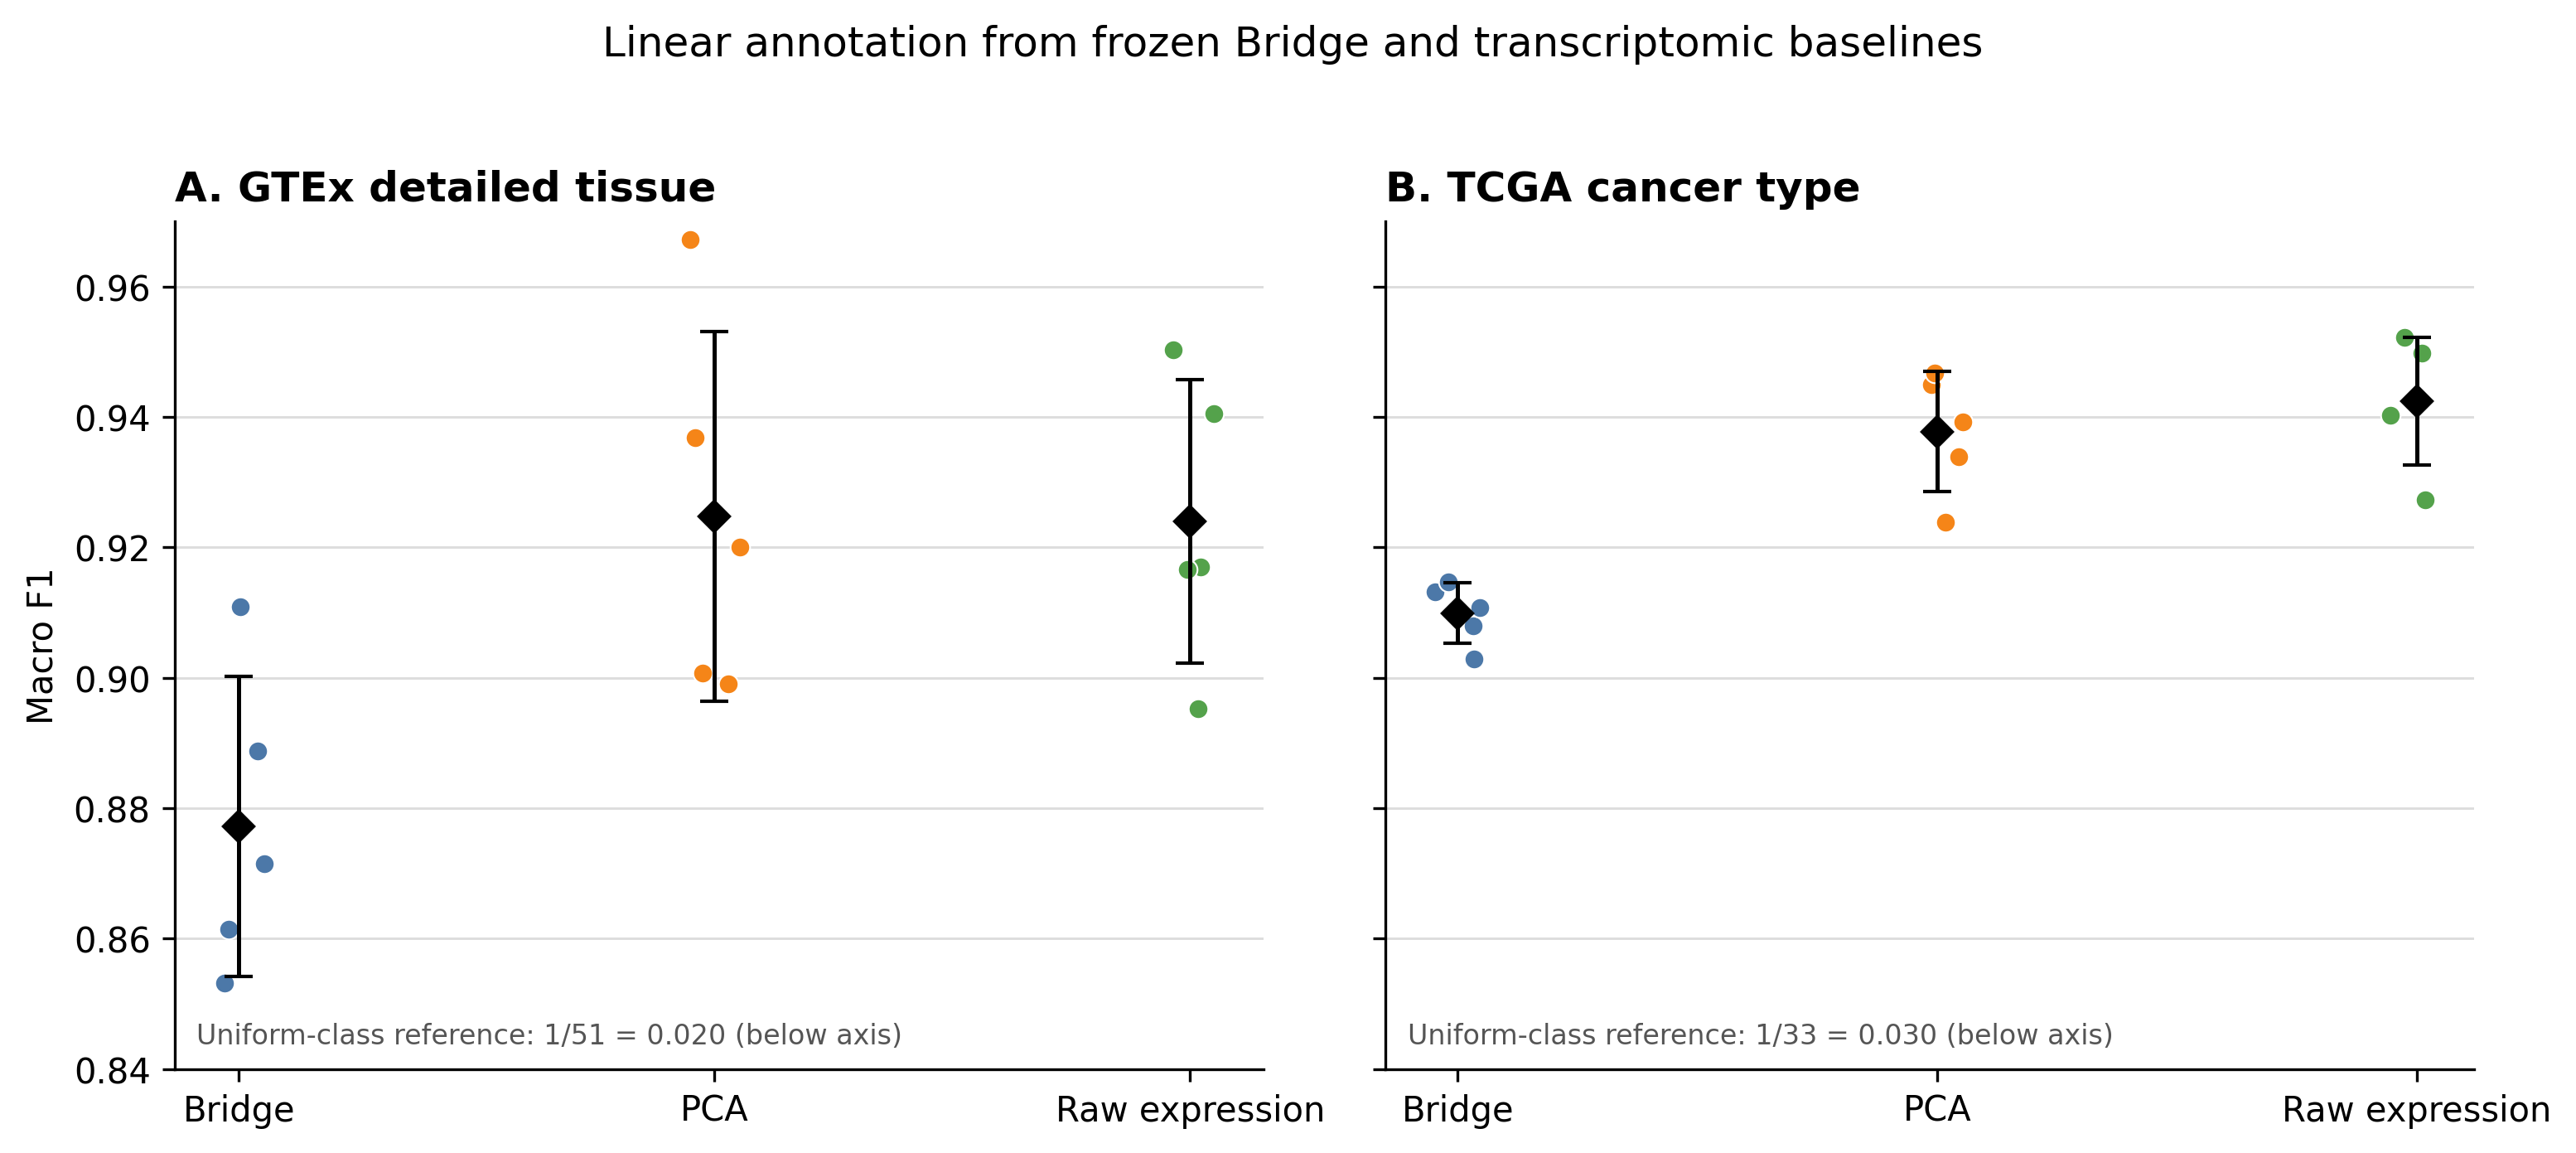

In [2]:
primary = metrics[metrics['task'].isin(['gtex_detailed', 'tcga_cancer'])].copy()
primary['task'] = primary['task'].map({'gtex_detailed': 'GTEx detailed', 'tcga_cancer': 'TCGA cancer'})
primary['representation'] = primary['representation'].map({'bridge': 'Bridge', 'pca': 'PCA', 'raw': 'Raw expression'})
display(primary[['task', 'representation', 'folds', 'accuracy_mean', 'accuracy_sd', 'macro_f1_mean', 'macro_f1_sd', 'weighted_f1_mean', 'weighted_f1_sd']].round(4))
display(Image(filename=str(FIGURES / 'main_annotation_macro_f1.png'), width=1000))

## Results

Frozen Bridge representations were strongly linearly separable: mean macro F1 was **0.877** across 51 detailed GTEx tissues and **0.910** across all 33 TCGA cancer types. The 512-dimensional Bridge embedding therefore retains substantial biological identity while reducing dimensionality approximately 29.6-fold relative to the 15,165-gene transcriptome. Descriptively, Bridge retained 94.9% of PCA macro-F1 performance on detailed GTEx and 97.0% on TCGA. These ratios do not establish representation superiority.

The negative comparison is equally important. PCA reached macro F1 of 0.925 on detailed GTEx and 0.938 on TCGA; raw expression reached 0.924 and 0.942. Bridge was below both baselines in every paired fold. Mean Bridge-minus-PCA / Bridge-minus-raw differences were −0.0476 / −0.0468 for detailed GTEx, −0.0278 / −0.0325 for TCGA, and −0.0359 / −0.0331 for supplementary broad GTEx. No post-hoc significance test was added for five paired folds.

bridge_minus_pca                 bridge_minus_raw          \
                          mean     min     max             mean     min   
task                                                                      
gtex_broad             -0.0359 -0.0456 -0.0163          -0.0331 -0.0495   
gtex_detailed          -0.0476 -0.0563 -0.0376          -0.0468 -0.0634   
tcga_cancer            -0.0278 -0.0321 -0.0210          -0.0325 -0.0390   

                       
                  max  
task                   
gtex_broad    -0.0146  
gtex_detailed -0.0338  
tcga_cancer   -0.0243

### Supplementary GTEx broad-tissue result

,representation,accuracy_mean,macro_f1_mean,weighted_f1_mean
0,bridge,0.9779,0.9265,0.9773
1,pca,0.9907,0.9623,0.9904
2,raw,0.9890,0.9595,0.9887


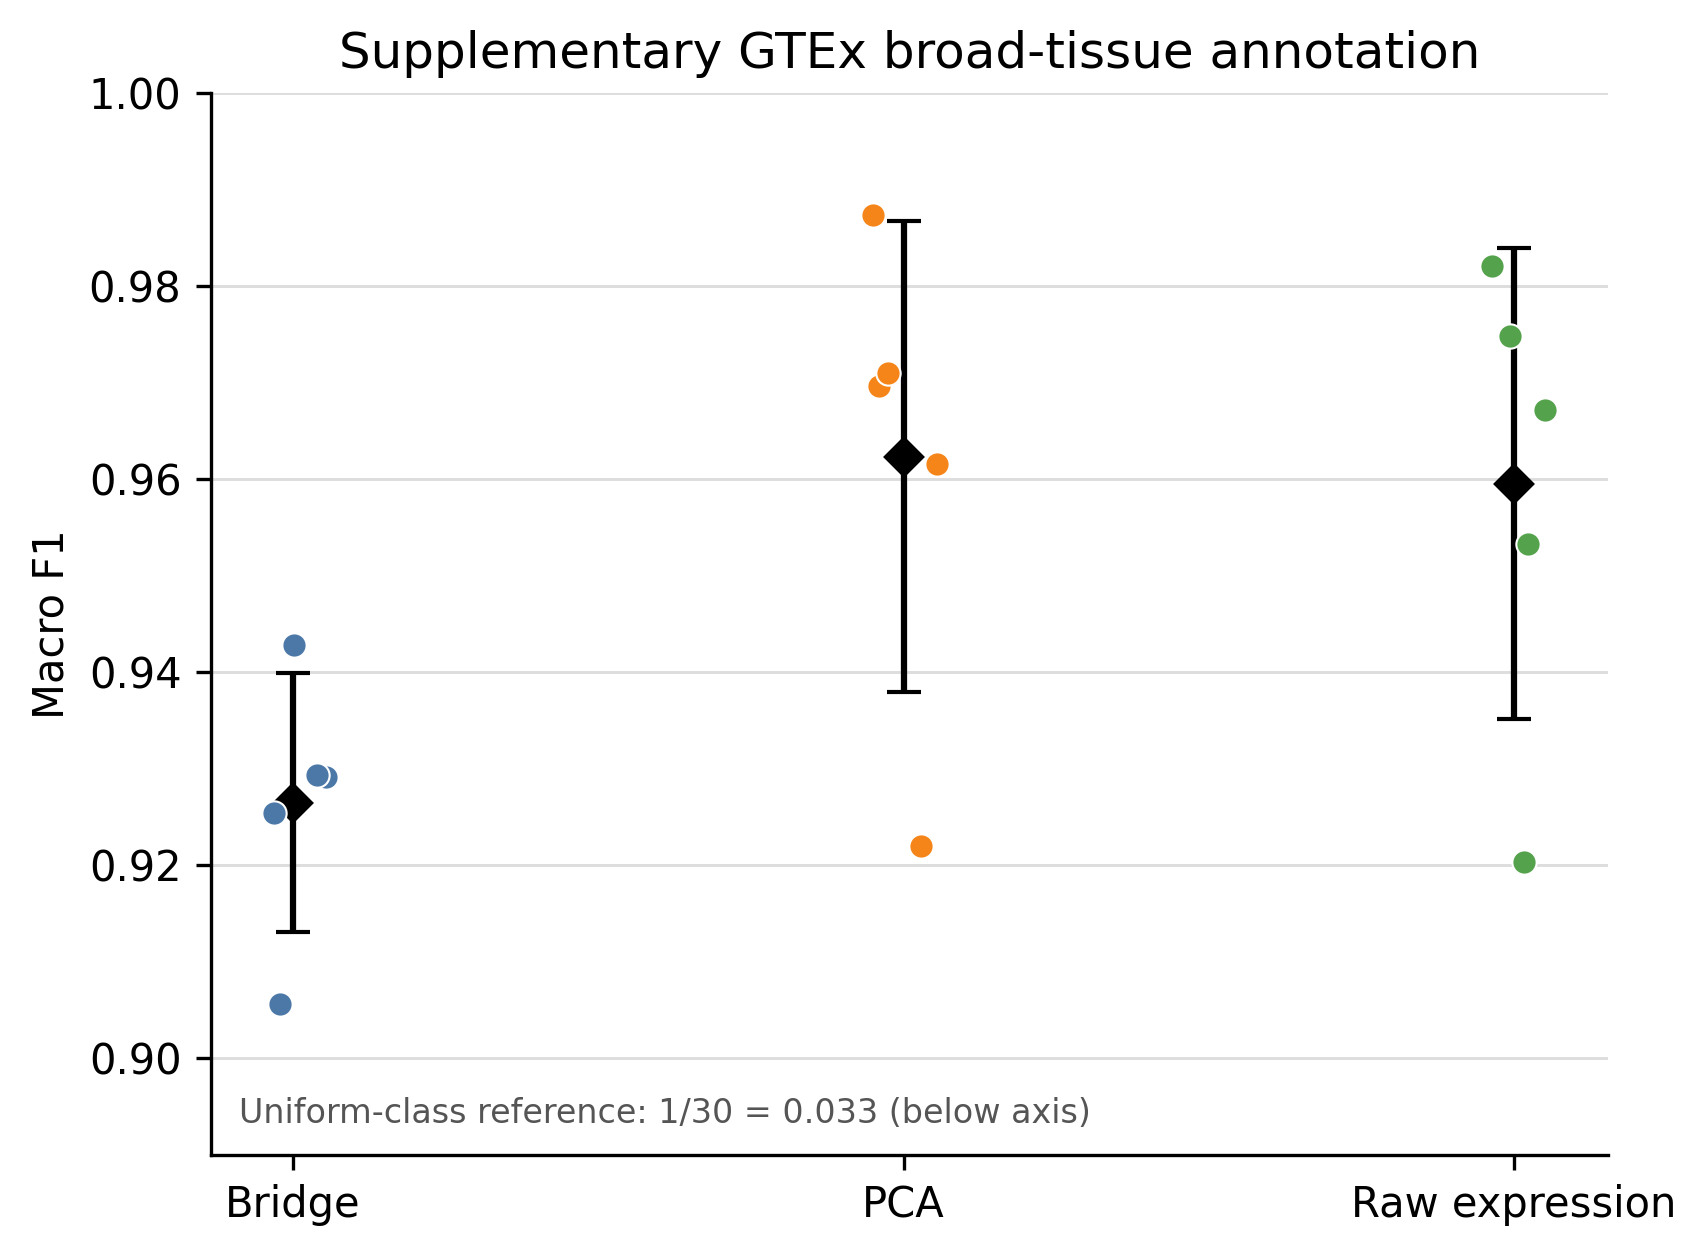

### Supplementary accuracy and weighted-F1 comparisons

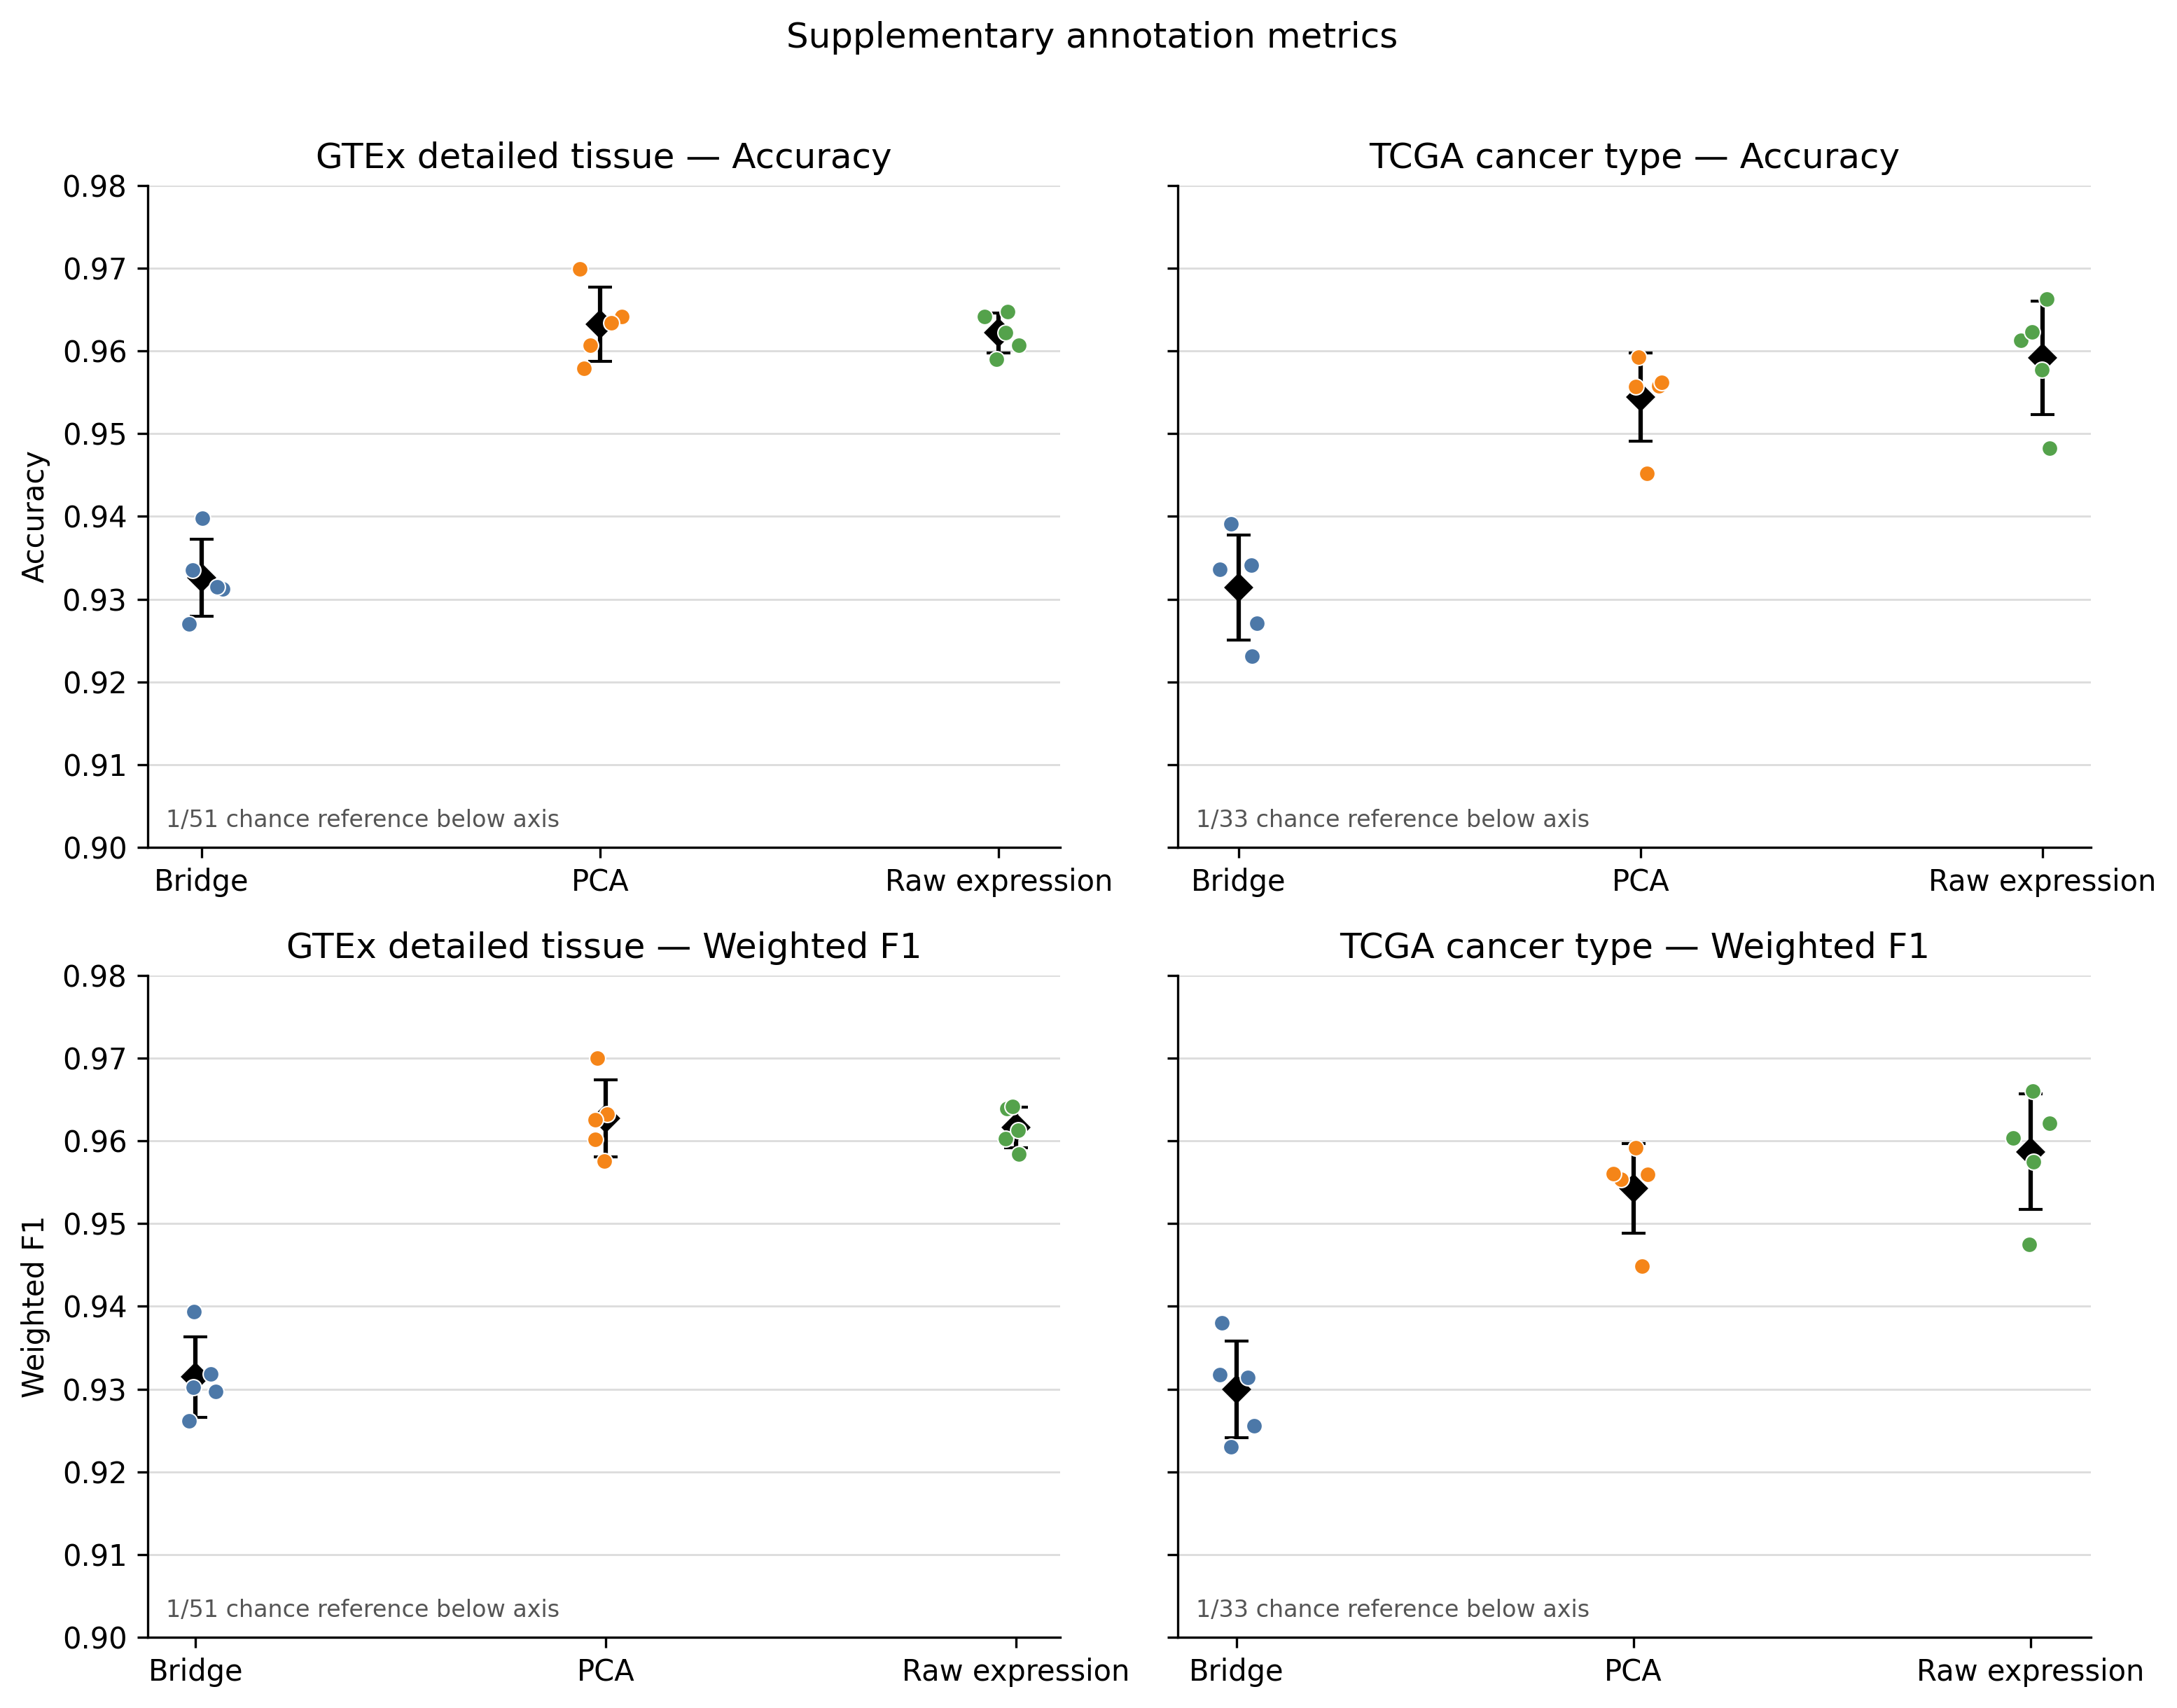

In [3]:
paired_summary = paired.groupby('task')[['bridge_minus_pca', 'bridge_minus_raw']].agg(['mean', 'min', 'max'])
display(paired_summary.round(4))
assert (paired[['bridge_minus_pca', 'bridge_minus_raw']].to_numpy() < 0).all()
broad = metrics[metrics['task'] == 'gtex_broad'][['representation', 'accuracy_mean', 'macro_f1_mean', 'weighted_f1_mean']].copy()
display(Markdown('### Supplementary GTEx broad-tissue result'))
display(broad.round(4))
display(Image(filename=str(FIGURES / 'supplementary_gtex_broad_macro_f1.png'), width=600))
display(Markdown('### Supplementary accuracy and weighted-F1 comparisons'))
display(Image(filename=str(FIGURES / 'supplementary_accuracy_weighted_f1.png'), width=950))

## Class-level behavior

Rare GTEx classes require caution: Cervix–Ectocervix has six profiles and Bridge F1=0, Cervix–Endocervix has five, and Fallopian Tube has seven. Approximately one observation can enter each held-out fold, so these estimates do not show that Bridge lacks cervical or fallopian information. Better-powered errors were largely between adjacent annotations, including gastroesophageal junction → esophagus muscularis, transverse → sigmoid colon, non-sun-exposed → sun-exposed skin, and related brain regions.

The clearest TCGA confusion was READ → COAD (106/166, 63.9%); the reverse COAD → READ error was 46/458 (10.0%). ESCA → STAD occurred in 41/184 patients (22.3%). These patterns indicate nearby transcriptional neighborhoods under this readout but are not mechanistic findings. CHOL is also uncertain because it contains only 36 patients.

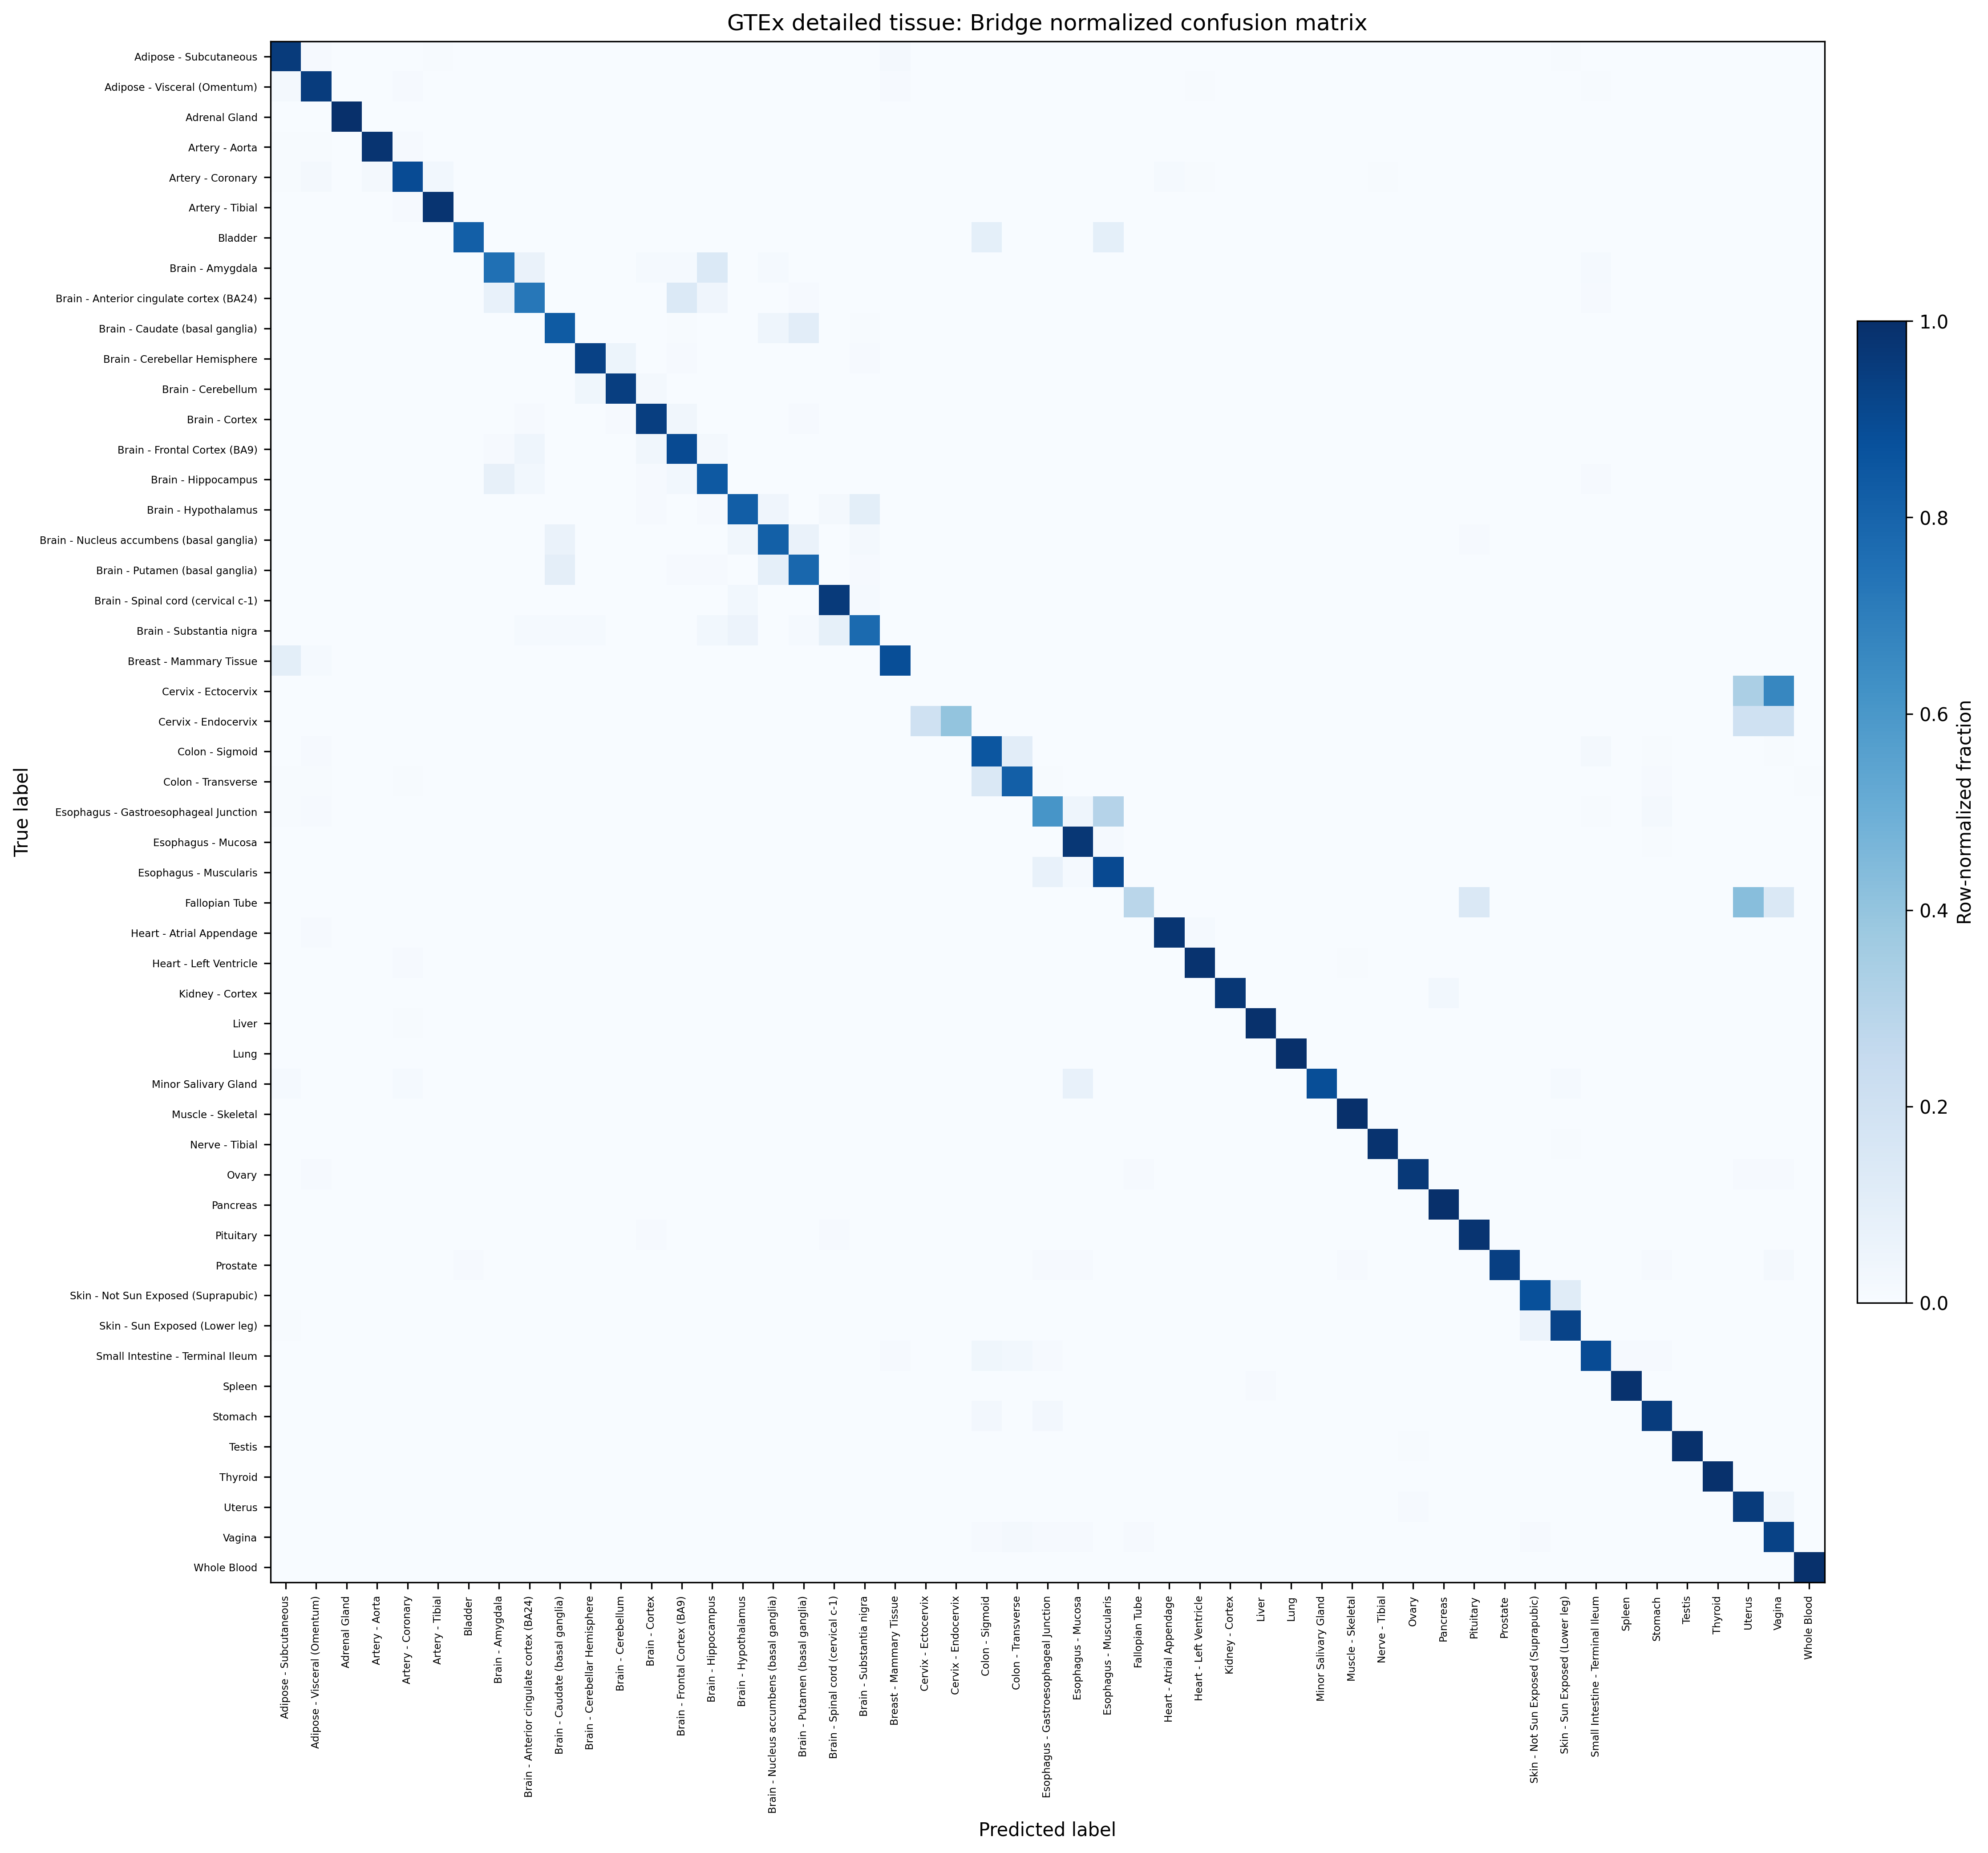

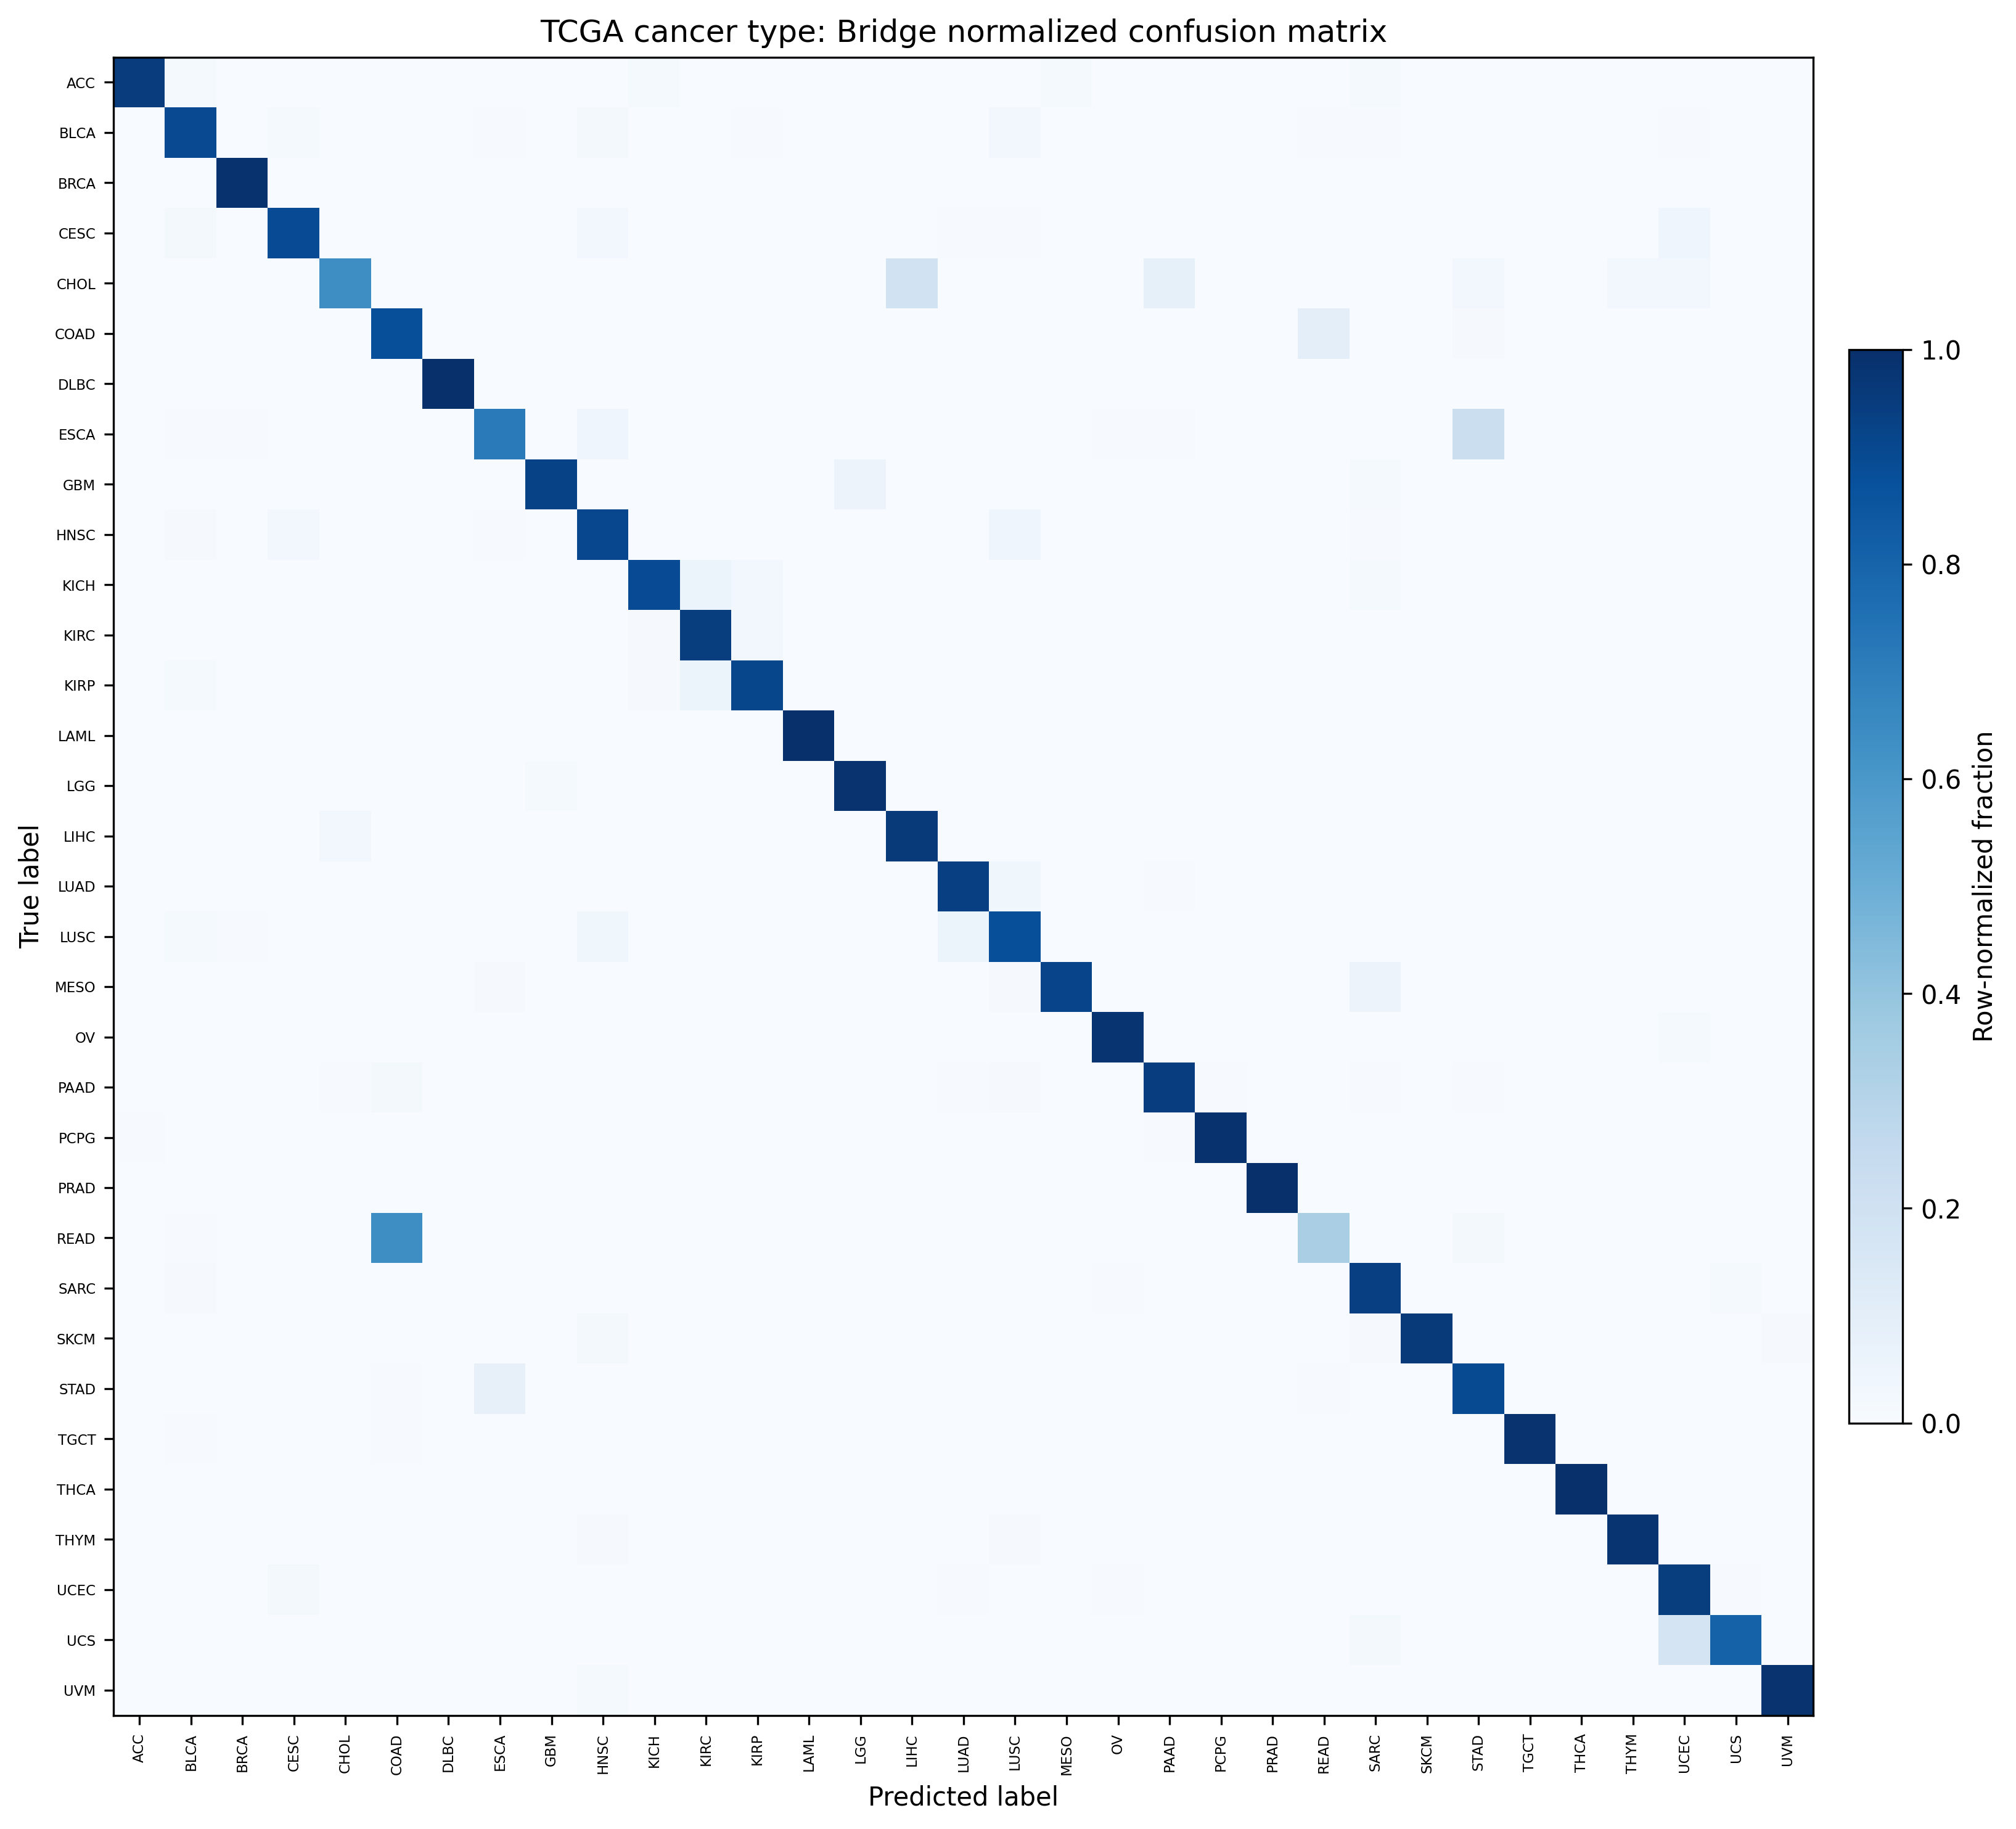

In [4]:
display(Image(filename=str(FIGURES / 'gtex_detailed_bridge_confusion_normalized.png'), width=950))
display(Image(filename=str(FIGURES / 'tcga_cancer_bridge_confusion_normalized.png'), width=850))

## Leakage controls and cached-evidence verification

GTEx donor IDs never cross folds, repeated biospecimens were removed, and TCGA contains one row per patient. PCA and all scalers were trained inside each fold. Bridge, PCA, and raw expression use identical held-out samples; Bridge remained frozen; and annotation labels were not used to construct representations. All 45 classifier fits converged.

For this publication package, all saved prediction rows were checked. Recomputed accuracy, macro F1, and weighted F1 matched the frozen fold tables within 1e-12, and held-out sample sets matched across representations. Prediction files were not repackaged because aggregate tables are sufficient for this report and avoid distributing sample identifiers.

In [5]:
display(pd.Series(validation, name='verification'))
qc = json.loads((DATA / 'final_qc.json').read_text())
assert all(qc.values())
assert validation['held_out_sample_sets_identical']
assert validation['duplicate_held_out_predictions'] == 0
assert max(validation['maximum_absolute_metric_difference'].values()) <= validation['metric_tolerance']
print('All packaged QC and verification assertions passed.')

prediction_rows_checked                                                           83124
fold_representation_groups_checked                                                   45
maximum_absolute_metric_difference    {'accuracy': 1.1102230246251565e-16, 'macro_f1...
metric_tolerance                                                                    0.0
held_out_sample_sets_identical                                                     True
duplicate_held_out_predictions                                                        0
Name: verification, dtype: object

All packaged QC and verification assertions passed.


## Limitations and scientific significance

ARCHS4 pretraining may contain public GTEx and/or TCGA expression profiles. Although pretraining used label-free masked-expression reconstruction rather than tissue or cancer labels, this benchmark demonstrates biological linear separability of the frozen representation—not guaranteed sample-unseen external generalization. Rare GTEx classes produce noisy fold-level F1, and uncertainty reflects one fixed five-fold split rather than independent model or pretraining replicates. GTEx-versus-TCGA normal/tumor classification remains deliberately out of scope because cohort, procurement, sequencing, and processing effects would be confounded with disease state.

## Conclusion

Frozen BridgeRNA representations preserve substantial tissue and cancer identity in a compact 512-dimensional vector. A fixed linear readout achieves macro F1 of 0.877 across 51 detailed GTEx tissues and 0.910 across 33 TCGA cancer types. PCA and raw expression remain more linearly separable for these straightforward annotation tasks, showing that Bridge preserves much—but not all—of the identity information accessible from the original transcriptome.